
# Creating Cohorts of Songs Using Spotify Data

## Course-End Project 2: Machine Learning

### Project Overview

Spotify uses information about songs and listening preferences
to help recommend music to its users. Grouping songs with similar
audio characteristics can help identify patterns that may be
useful for music recommendations.

This project examines a dataset of Rolling Stones songs
collected through Spotify's API. The analysis will explore
song popularity, audio features, and relationships between
variables before applying clustering algorithms to group
similar songs.

### Project Objectives

1. Inspect and clean the dataset.
2. Perform exploratory data analysis (EDA).
3. Identify albums containing the most popular songs.
4. Examine relationships between popularity and audio features.
5. Explore dimensionality reduction using PCA.
6. Determine an appropriate number of clusters.
7. Apply clustering algorithms and interpret the results.


In [1]:
import pandas as pd
import numpy as np

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:

# Load the Rolling Stones Spotify dataset

from pathlib import Path

# Get the notebook's current working directory
current_dir = Path.cwd()

# Find the project folder
if current_dir.name == "notebooks":
    project_root = current_dir.parent
elif current_dir.name == "spotify_song_clustering":
    project_root = current_dir
else:
    project_root = current_dir / "machine_learning" / "spotify_song_clustering"

# Define dataset path
data_path = project_root / "data" / "raw" / "rolling_stones_spotify.csv"

# Verify the path
print("Dataset location:", data_path)
print("File exists:", data_path.exists())

# Load dataset
df = pd.read_csv(data_path)

print("\nDataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

display(df.head())


Dataset location: c:\Users\juanb\Documents\Python_Course_End_Projects\machine_learning\spotify_song_clustering\data\raw\rolling_stones_spotify.csv
File exists: True

Dataset loaded successfully.
Rows: 1610
Columns: 18


,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106



## 1. Data Inspection and Cleaning

Before performing exploratory data analysis or clustering,
the dataset must be examined for potential quality issues.

This section reviews the dataset's structure, data types,
missing values, duplicate records, and numerical features
to determine whether any cleaning is necessary.


In [3]:
# Inspect dataset dimensions and structures

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe().T)

Dataset Shape: (1610, 18)

Column Names:
['Unnamed: 0', 'name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   str    
 2   album             1610 non-null   str    
 3   release_date      1610 non-null   str    
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   str    
 6   uri               1610 non-null   str    
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1610.0,804.500000,464.911282,0.000000,402.250000,804.50000,1206.75000,1609.000
track_number,1610.0,8.613665,6.560220,1.000000,4.000000,7.00000,11.00000,47.000
acousticness,1610.0,0.250475,0.227397,0.000009,0.058350,0.18300,0.40375,0.994
danceability,1610.0,0.468860,0.141775,0.104000,0.362250,0.45800,0.57800,0.887
energy,1610.0,0.792352,0.179886,0.141000,0.674000,0.84850,0.94500,0.999
instrumentalness,1610.0,0.164170,0.276249,0.000000,0.000219,0.01375,0.17900,0.996
liveness,1610.0,0.491730,0.349100,0.021900,0.153000,0.37950,0.89375,0.998
loudness,1610.0,-6.971615,2.994003,-24.408000,-8.982500,-6.52300,-4.60875,-1.014
speechiness,1610.0,0.069512,0.051631,0.023200,0.036500,0.05120,0.08660,0.624
tempo,1610.0,126.082033,29.233483,46.525000,107.390750,124.40450,142.35575,216.304


In [4]:
# Missing Values Check

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

display(missing_summary)

print("Total missing values:", missing_values.sum())

,Missing Values,Missing Percentage
Unnamed: 0,0,0.0
name,0,0.0
album,0,0.0
release_date,0,0.0
track_number,0,0.0
id,0,0.0
uri,0,0.0
acousticness,0,0.0
danceability,0,0.0
energy,0,0.0


Total missing values: 0


In [5]:
# Duplicate Analysis

duplicate_rows = df.duplicated().sum()
duplicate_ids = df["id"].duplicated().sum()

print("Duplicate Rows:", duplicate_rows)
print("Duplicate Spotify IDs:", duplicate_ids)

if duplicate_ids > 0:
    display(df[df["id"].duplicated(keep=False)])

Duplicate Rows: 0
Duplicate Spotify IDs: 0


In [6]:
# Check Unecessary Columns

is_saved_index = np.array_equal(
    df["Unnamed: 0"].to_numpy(),
    np.arange(len(df))
)

print("Unnamed column matches row index:", is_saved_index)

Unnamed column matches row index: True



## 2. Data Cleaning

The initial inspection found no missing values, duplicate rows,
or duplicate Spotify track IDs.

The dataset contains an additional column named `Unnamed: 0`
that duplicates the row index. This column does not provide
information about the songs and will be removed.

A separate copy of the dataset will be used for cleaning
to preserve the original data.


In [7]:
# Create a working copy of the original dataset for further analysis

df_clean = df.copy()

# Remove the unecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Compare dataset dimensions
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

# Preview the updated dataset
display(df_clean.head())

Original dataset shape: (1610, 18)
Clean dataset shape: (1610, 17)


,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


In [8]:
# Convert release_date into a datetime column

df_clean["release_date"] = pd.to_datetime(
    df_clean["release_date"],
    errors='coerce'
    )

# Extract the release year
df_clean["release_year"] = df_clean["release_date"].dt.year

# Check the Results
print("Release date data type:", df_clean["release_date"].dtype)

print("\nInvalid or missing dates:", df_clean["release_date"].isnull().sum())

print("\nRelease year range:", df_clean["release_year"].min(), "-", df_clean["release_year"].max())

display(
df_clean[["name", "album", "release_date", "release_year"]].head()
)

Release date data type: datetime64[us]

Invalid or missing dates: 0

Release year range: 1964 - 2022


,name,album,release_date,release_year
0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,2022
1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2022
2,Start Me Up - Live,Licked Live In NYC,2022-06-10,2022
3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,2022
4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,2022



### Release Date Findings

The release date column was successfully converted to a datetime
format, with no invalid or missing dates identified.

The dataset contains album release dates ranging from 1964 to
2022. A release year column was also created to support the
analysis of song popularity and audio characteristics over time.

Since the dataset includes live recordings and reissued albums,
release dates may not always represent when a song was
originally recorded.


In [9]:
# Validate numerical feature ranges

# Audio features expected to range from 0 to 1
bounded_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "speechiness",
    "valence"
]

# Check for values outside the expected range
for feature in bounded_features:
    invalid_count = (
        (df_clean[feature] < 0) |
        (df_clean[feature] > 1)
    ).sum()

    print(f"{feature}: {invalid_count} invalid values")

# Check additional numerical features
print(
    "\nInvalid popularity values:",
    ((df_clean["popularity"] < 0) |
    (df_clean["popularity"] > 100)).sum()
)

print(
    "Negative tempo values",
    (df_clean["tempo"] < 0).sum()
)

print(
    "Non-positive duration",
    (df_clean["duration_ms"] <= 0).sum()
)

print(
    "Non-positive track numbers",
    (df_clean["track_number"] <= 0).sum()
)

acousticness: 0 invalid values
danceability: 0 invalid values
energy: 0 invalid values
instrumentalness: 0 invalid values
liveness: 0 invalid values
speechiness: 0 invalid values
valence: 0 invalid values

Invalid popularity values: 0
Negative tempo values 0
Non-positive duration 0
Non-positive track numbers 0



### Numerical Feature Validation

The numerical validation checks did not identify any values outside
the expected ranges for the seven bounded audio features or
the popularity scores.

No negative tempo values, non-positive durations, or invalid
track numbers were found.

Although these checks did not identify range errors, further
analysis is needed to determine whether unusually high or low
values could influence the clustering results.


In [10]:
# Examine numerical feature distributions

numeric_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_ms"
]

# Calculate descriptive statistics
numeric_summary = df_clean[numeric_features].agg(
    ["mean", "median", "std", "min", "max"]
).T

# Display the results
display(numeric_summary.round(3))


,mean,median,std,min,max
acousticness,0.250,0.183,0.227,0.000,0.994
danceability,0.469,0.458,0.142,0.104,0.887
energy,0.792,0.848,0.180,0.141,0.999
instrumentalness,0.164,0.014,0.276,0.000,0.996
liveness,0.492,0.380,0.349,0.022,0.998
loudness,-6.972,-6.523,2.994,-24.408,-1.014
speechiness,0.070,0.051,0.052,0.023,0.624
tempo,126.082,124.404,29.233,46.525,216.304
valence,0.582,0.583,0.231,0.000,0.974
popularity,20.788,20.000,12.427,0.000,80.000



### Descriptive Statistics Findings

The descriptive statistics show noticeable differences across
the audio features.

Energy is relatively high, with an average of 0.792 and a
median of 0.848. This suggests that many recordings in the
dataset have high energy levels.

Instrumentalness has a mean of 0.164 but a much lower median
of 0.014. This suggests that most recordings have low
instrumentalness scores, while some have considerably
higher values.

Liveness varies widely across the dataset, which may help
distinguish live performances from studio recordings.

Song duration also varies substantially. The average duration
is approximately 4.3 minutes, while the longest recording
is approximately 16.4 minutes.

These differences suggest that further analysis of feature
distributions and potential outliers is necessary before
clustering.


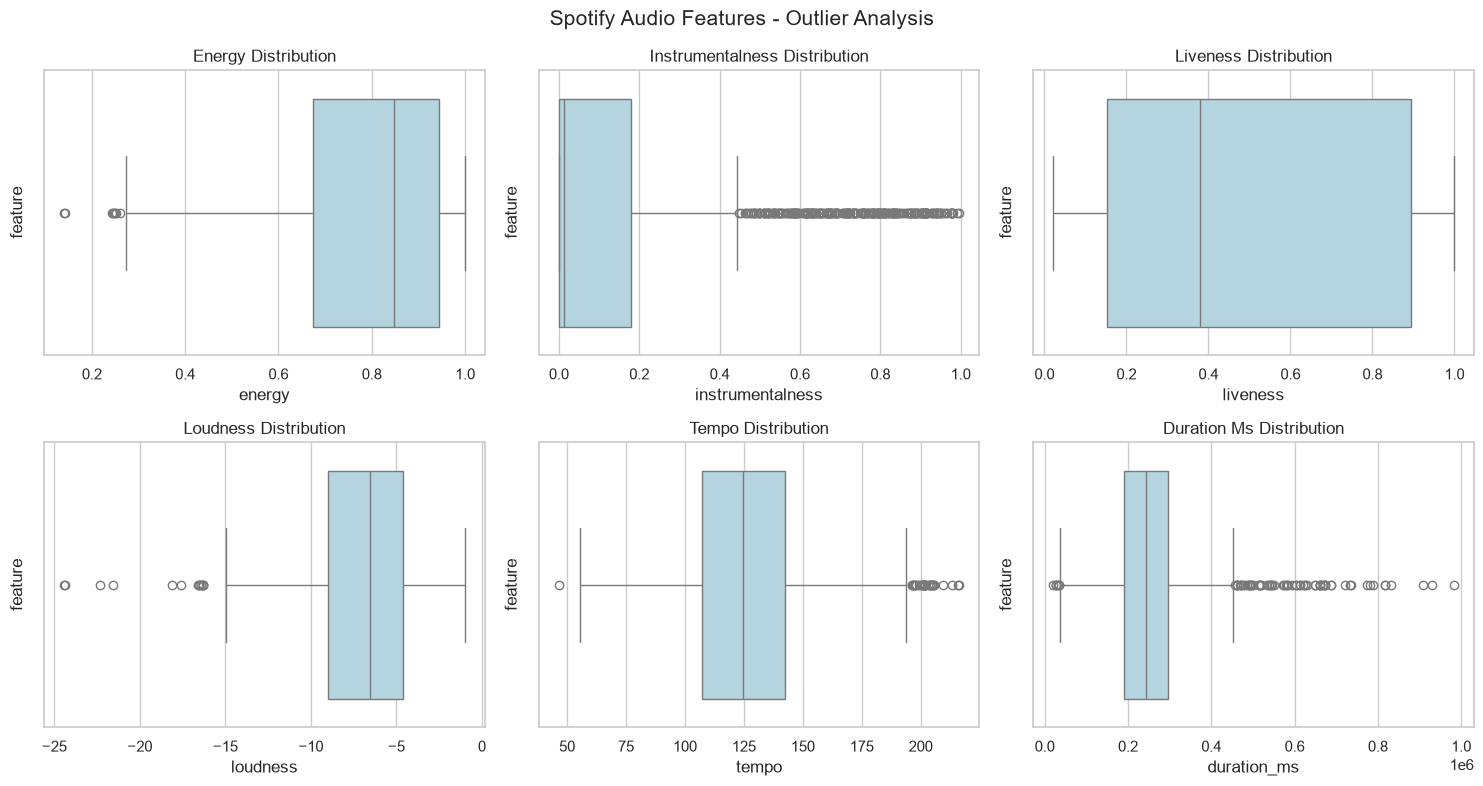

In [11]:
# Visualize potential outliers

features_to_plot = [
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "tempo",
    "duration_ms"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flatten(), features_to_plot):
    sns.boxplot(
        x=df_clean[feature],
        ax=ax,
        color='lightblue'
    )
    ax.set_title(f"{feature.replace('_', ' ').title()} Distribution")
    ax.set_ylabel("feature")

plt.suptitle(
    "Spotify Audio Features - Outlier Analysis",
    fontsize=15
    )

plt.tight_layout()
plt.show()


### Outlier Detection Using the IQR Method

Boxplots were used to examine the distributions of selected
numerical features.

Potential outliers were observed in energy, instrumentalness,
loudness, tempo, and duration. Liveness did not show obvious
outliers.

The interquartile range (IQR) method will be used to calculate
the number of potential outliers in each feature.

These observations will be investigated before deciding
whether any records should be removed or transformed.


In [12]:
# Identify potential outliers using IRQ

outlier_results = []

for feature in features_to_plot:

    # Calcultate the first and third quartiles
    Q1 = df_clean[feature].quantile(0.25)
    Q3 = df_clean[feature].quantile(0.75)

    # Calculate the interquartile range (IQR)
    IQR = Q3 - Q1

    # Determine the outliar boundries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify observations outside the boundaries
    outliers = (
        (df_clean[feature] < lower_bound) |
        (df_clean[feature] > upper_bound)
    )

    # Store the results
    outlier_results.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    })

# Convert results into a DataFrame
outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(3))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,energy,0.268,1.351,8,0.497
1,instrumentalness,-0.268,0.447,272,16.894
2,liveness,-0.958,2.005,0,0.000
3,loudness,-15.543,1.952,14,0.870
4,tempo,54.943,194.803,34,2.112
5,duration_ms,33552.875,452379.875,76,4.720



### Outlier Analysis Findings

The IQR analysis identified potential outliers in five of the
six numerical features examined.

Instrumentalness had the highest number of outliers, with
272 recordings (16.89%). Duration had 76 (4.72%), followed
by tempo with 34 (2.11%). Loudness and energy had relatively
few outliers, while liveness had none.

These observations do not necessarily represent data errors.
The dataset contains different types of musical recordings,
and unusual audio characteristics may be important for
identifying meaningful song groups.

Since the earlier validation checks did not identify values
outside the expected numerical ranges, the observations
will be retained for the initial clustering analysis.

The influence of extreme observations will be considered
during feature preparation and model evaluation.


In [13]:

# Step 4.10 - Investigate unusually long recordings

# Select the 10 longest tracks
longest_tracks = df_clean.nlargest(
    10,
    "duration_ms"
).copy()

# Create a new column for duration in minutes
longest_tracks["duration_minutes"] = (
    longest_tracks["duration_ms"] / 60000
).round(2)

# Verify that the new column exists
print("Available columns:")
print(longest_tracks.columns.tolist())

# Display the 10 longest tracks
display(
    longest_tracks[
        [
            "name",
            "album",
            "release_year",
            "duration_minutes",
            "popularity"
        ]
    ]
)


Available columns:
['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms', 'release_year', 'duration_minutes']


,name,album,release_year,duration_minutes,popularity
220,Miss You - Live,Bridges To Bremen (Live),2019,16.36,21
460,Midnight Rambler - Live,Havana Moon (Live),2016,15.49,22
537,Miss You - Live,Totally Stripped - Paris (Live),2016,15.12,11
482,Miss You - Live,Totally Stripped - Brixton (Live),2016,13.87,14
297,Miss You - Live,Voodoo Lounge Uncut (Live),2018,13.60,16
325,Miss You - Live,Voodoo Lounge Uncut (Live),2018,13.60,9
1175,Midnight Rambler - Live At University Of Leeds...,Sticky Fingers (Super Deluxe),1971,13.15,17
8,Midnight Rambler - Live,Licked Live In NYC,2022,13.02,30
183,Midnight Rambler - Live / Forest National Aren...,Goats Head Soup (Deluxe),2020,12.89,20
111,Midnight Rambler - Live,A Bigger Bang (Live),2021,12.25,19



### Investigation of Duration Outliers

The ten longest tracks were examined to determine whether
their durations represented possible data errors.

All ten recordings were labeled as live performances. The
longest was "Miss You - Live" from Bridges To Bremen, with
a duration of approximately 16.36 minutes.

Several versions of "Miss You" and "Midnight Rambler"
appeared among the longest recordings. This suggests that
extended live performances contribute to the unusually
high duration values.

There is no clear evidence that these durations are
incorrect, so the recordings will be retained for the
initial clustering analysis.

The effect of unusually long tracks will be considered
when preparing features and evaluating the clusters.


In [14]:
# Final data cleaning verification

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate Spotify IDs:", df_clean["id"].duplicated().sum())

print("\nColumn data types:")
print(df_clean.dtypes)

print("\nDataset preview:")
display(df_clean.head())

Original dataset shape: (1610, 18)
Cleaned dataset shape: (1610, 18)

Missing values: 0
Duplicate rows: 0
Duplicate Spotify IDs: 0

Column data types:
name                           str
album                          str
release_date        datetime64[us]
track_number                 int64
id                             str
uri                            str
acousticness               float64
danceability               float64
energy                     float64
instrumentalness           float64
liveness                   float64
loudness                   float64
speechiness                float64
tempo                      float64
valence                    float64
popularity                   int64
duration_ms                  int64
release_year                 int32
dtype: object

Dataset preview:


,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms,release_year
0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640,2022
1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173,2022
2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160,2022
3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880,2022
4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106,2022



## 3. Exploratory Data Analysis

### 3.1 Song Popularity Distribution

The first objective is to examine song popularity across the
dataset. Understanding the distribution will help determine
a reasonable threshold for identifying popular songs before
comparing albums.


Popularity Statistics:


count    1610.000000
mean       20.788199
std        12.426859
min         0.000000
25%        13.000000
50%        20.000000
75%        27.000000
max        80.000000
Name: popularity, dtype: float64

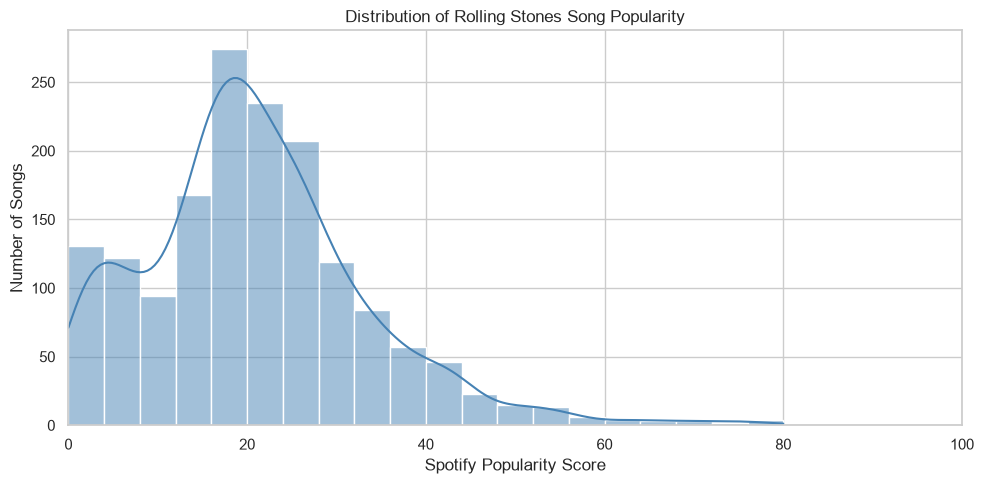

In [15]:

# Song Popularity Distribution

# Display popularity statistics
print("Popularity Statistics:")
display(df_clean["popularity"].describe())

# Create a histogram using ONLY the popularity column
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="popularity",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Rolling Stones Song Popularity")
plt.xlabel("Spotify Popularity Score")
plt.ylabel("Number of Songs")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()



### Song Popularity Distribution Findings

The popularity distribution is right-skewed, with most
recordings concentrated between approximately 10 and 30.

The average popularity score is 20.79, while the median is
20. The mean being slightly higher than the median is
consistent with the right-skewed distribution.

A relatively small number of recordings have popularity
scores above 40, with the highest score reaching 80.

These findings suggest that popularity is not evenly
distributed across the dataset. A smaller group of tracks
has substantially higher popularity than the majority.

This distribution will help guide the selection of a
popularity threshold for identifying albums containing
popular songs.


In [16]:
# Eveluate potential popularity threshholds

percentiles = [0.75, 0.80, 0.90, 0.95]

threshold_results = []

for percentile in percentiles:
    threshold = df_clean["popularity"].quantile(percentile)

    popular_count = (
        df_clean["popularity"] >= threshold
    ).sum()

    threshold_results.append({
        "Percentile": f"{percentile:0%}",
        "Popularity Threshold": threshold,
        "Number of Songs": popular_count,
        "Percentage of Dataset": (
            popular_count / len(df_clean) * 100
        )
    })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary.round(2))

,Percentile,Popularity Threshold,Number of Songs,Percentage of Dataset
0,75.000000%,27.0,429,26.65
1,80.000000%,29.0,348,21.61
2,90.000000%,36.0,176,10.93
3,95.000000%,43.0,84,5.22



### Popularity Threshold Selection

Multiple percentile-based popularity thresholds were
evaluated to identify relatively popular recordings.

The 90th percentile was selected as the primary threshold,
corresponding to a popularity score of 36.

Using this threshold, 176 of the 1,610 tracks (10.93%)
qualify as popular relative to the dataset.

This approach focuses the album recommendation analysis
on recordings with comparatively high popularity scores.

Since popularity values contain ties, the qualifying
percentage is slightly greater than 10%.

The selected threshold is specific to this dataset and
does not represent an official Spotify popularity category.


In [17]:
# Indentify albums with the most popular songs

# Define the popularity threshold
popularity_threshold = df_clean["popularity"].quantile(0.90)

# Filter tracks meeting the threshold
popular_songs = df_clean[
    df_clean["popularity"] >= popularity_threshold
].copy()

# Count popular tracks by album
popular_album_counts = (
    popular_songs
    .groupby("album")
    .agg(
        popular_song_count=("id", "nunique"),
        average_popularity=("popularity", "mean")
    )
    .sort_values(
        by=["popular_song_count", "average_popularity"],
        ascending=False
        )
        .reset_index())

print("Popularity Threshold:", popularity_threshold)
print("Number of qualifying tracks:", len(popular_songs))

display(popular_album_counts.head(10))

Popularity Threshold: 36.0
Number of qualifying tracks: 176


,album,popular_song_count,average_popularity
0,Exile On Main Street (2010 Re-Mastered),18,44.166667
1,Sticky Fingers (Remastered),10,53.300000
2,Some Girls,10,48.100000
3,Tattoo You (2009 Re-Mastered),10,47.600000
4,Beggars Banquet (50th Anniversary Edition),10,43.700000
5,Let It Bleed,9,50.444444
6,Honk (Deluxe),8,42.875000
7,Aftermath,6,50.333333
8,Let It Bleed (50th Anniversary Edition / Remas...,6,40.833333
9,Out Of Our Heads,5,50.800000



### Album Popularity Analysis Findings

Albums were ranked by the number of unique Spotify tracks
meeting the selected popularity threshold of 36.

Exile On Main Street (2010 Re-Mastered) ranked first with
18 qualifying tracks and an average popularity score of 44.17.

Four albums tied for second with 10 qualifying tracks each:
Sticky Fingers (Remastered), Some Girls, Tattoo You
(2009 Re-Mastered), and Beggars Banquet
(50th Anniversary Edition).

Sticky Fingers (Remastered) was selected as the second
recommendation because it had the highest average popularity
among the tied albums, at 53.30.

Based on these criteria, the recommended albums are:

1. Exile On Main Street (2010 Re-Mastered)
2. Sticky Fingers (Remastered)

These recommendations are based on track popularity within
the dataset rather than individual listener preferences.


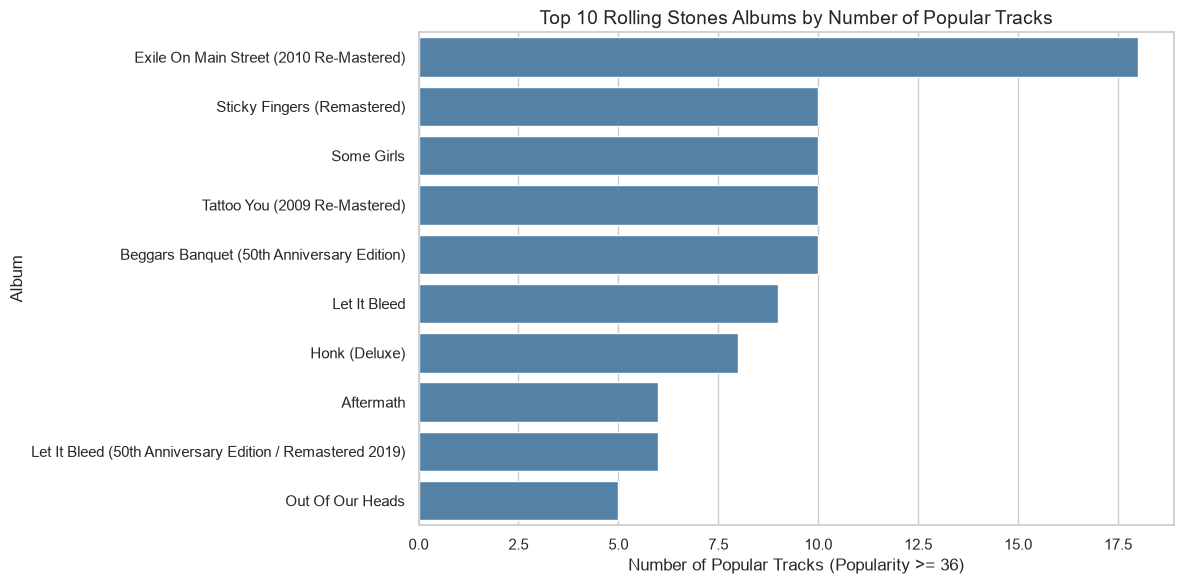

In [18]:

# Visualize albums with the most popular tracks

top_albums = popular_album_counts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_albums,
    x="popular_song_count",
    y="album",
    color="steelblue"
)

plt.title(
    "Top 10 Rolling Stones Albums by Number of Popular Tracks",
    fontsize=14
)

plt.xlabel("Number of Popular Tracks (Popularity >= 36)")
plt.ylabel("Album")

plt.tight_layout()
plt.show()



### 3.3 Album Popularity Percentage Analysis

The previous analysis ranked albums by their total number
of popular tracks.

However, albums may contain different numbers of tracks.
An album with more recordings has more opportunities to
contain popular songs.

To account for this difference, the percentage of popular
tracks will be calculated for each album.

This provides another perspective when evaluating album
recommendations.


In [20]:

# Step 5.5 - Calculate popular-track percentages by album

# Count the total number of unique tracks on each album
album_totals = (
    df_clean.groupby("album")["id"]
    .nunique()
    .reset_index(name="total_tracks")
)

# Count the number of popular tracks on each album
album_popular = (
    popular_songs.groupby("album")["id"]
    .nunique()
    .reset_index(name="popular_tracks")
)

# Combine both summaries
album_comparison = album_totals.merge(
    album_popular,
    on="album",
    how="left"
)

# Albums without qualifying tracks receive a count of zero
album_comparison["popular_tracks"] = (
    album_comparison["popular_tracks"]
    .fillna(0)
    .astype(int)
)

# Calculate the percentage of popular tracks
album_comparison["popular_percentage"] = (
    album_comparison["popular_tracks"]
    / album_comparison["total_tracks"]
    * 100
).round(2)

# Rank albums by popular-track count and percentage
album_comparison = album_comparison.sort_values(
    by=["popular_tracks", "popular_percentage"],
    ascending=False
)

# Display the top 10 albums
display(album_comparison.head(10))


,album,total_tracks,popular_tracks,popular_percentage
26,Exile On Main Street (2010 Re-Mastered),18,18,100.00
7,Beggars Banquet (50th Anniversary Edition),10,10,100.00
61,Some Girls,10,10,100.00
68,Sticky Fingers (Remastered),10,10,100.00
74,Tattoo You (2009 Re-Mastered),11,10,90.91
45,Let It Bleed,18,9,50.00
40,Honk (Deluxe),47,8,17.02
46,Let It Bleed (50th Anniversary Edition / Remas...,9,6,66.67
4,Aftermath,11,6,54.55
12,Black And Blue (Remastered 2009),8,5,62.50



### Album Popularity Percentage Findings

Popular-track percentages were calculated to account for
differences in the total number of tracks across albums.

Exile On Main Street (2010 Re-Mastered) had 18 popular tracks
out of 18 total, resulting in a 100% qualification rate.

Sticky Fingers (Remastered), Some Girls, and Beggars Banquet
(50th Anniversary Edition) also had 100% qualification rates,
with 10 qualifying tracks each.

Honk (Deluxe), despite containing 47 tracks, had only eight
qualifying tracks, representing approximately 17.02% of
its track listing.

These results support the original recommendations of
Exile On Main Street and Sticky Fingers.

Exile On Main Street has the highest number of qualifying
tracks, while Sticky Fingers has the highest average popularity
among the albums tied for second place.

The findings are based on the selected dataset-relative
popularity threshold of 36.



### 3.4 Audio Feature Distribution Analysis

The distributions of Spotify's audio features will be
examined to better understand the musical characteristics
represented in the dataset.

Histograms will be used to identify common feature values,
skewed distributions, and potential differences between
recordings.

These findings will help guide feature selection and
preprocessing before applying clustering algorithms.


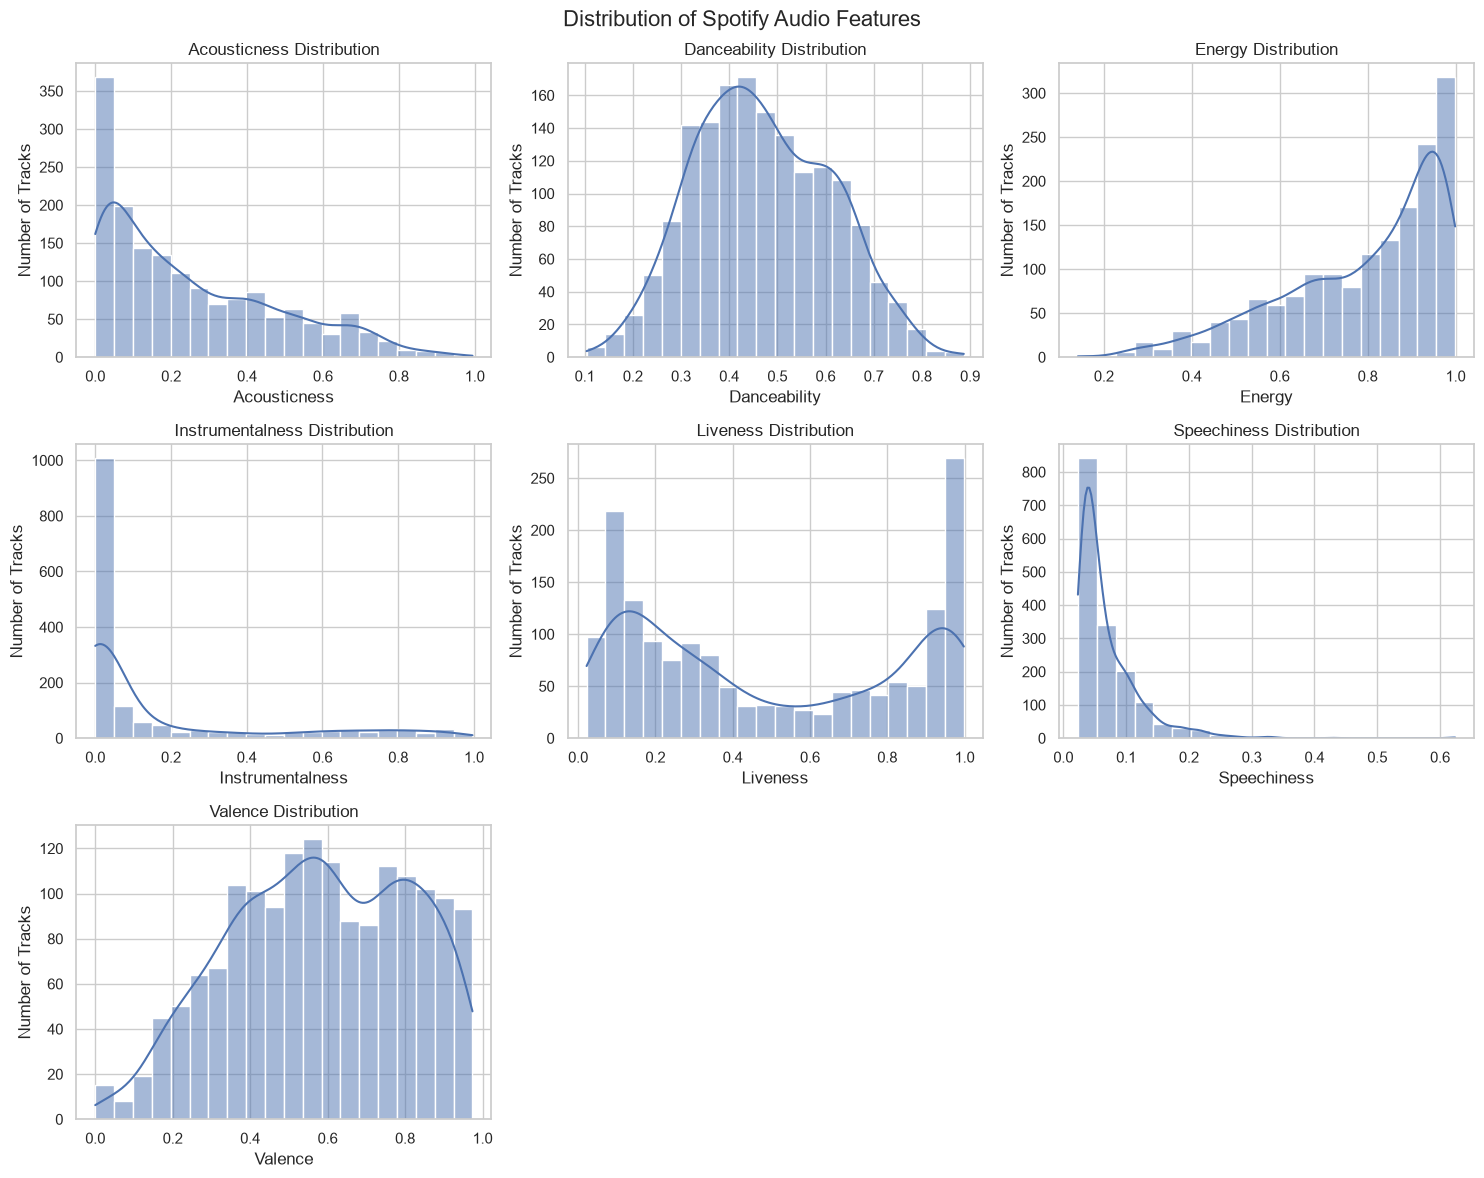

In [21]:
# Visualize Spotofy audio feature distributions

audio_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "speechiness",
    "valence"
]

# Create a grid of features histograms
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, feature in zip(axes.flatten(), audio_features):
    sns.histplot(
        data=df_clean,
        x=feature,
        bins=20,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{feature.title()} Distribution")
    ax.set_xlabel(feature.title())
    ax.set_ylabel("Number of Tracks")

# Hide unused subplot spaces
for ax in axes.flatten()[len(audio_features):]:
    ax.set_visible(False)

plt.suptitle(
    "Distribution of Spotify Audio Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


### Audio Feature Distribution Findings

The audio feature distributions reveal several patterns
across the Rolling Stones recordings.

Acousticness is right-skewed, with most tracks having
relatively low acousticness scores. This suggests that
the dataset contains more recordings with less prominent
acoustic characteristics.

Danceability is concentrated around moderate values,
while energy is left-skewed, with many tracks scoring
near the upper end of the scale.

Instrumentalness and speechiness are strongly right-skewed,
with most tracks having low values.

Liveness displays a roughly U-shaped distribution, with
concentrations at both low and high values. This may reflect
differences between studio and live recordings.

Valence shows a broad distribution, indicating variation
in the musical positivity of the tracks.

These findings suggest that liveness, energy, acousticness,
instrumentalness, and other audio features may help
distinguish meaningful song cohorts.

The distributions will be considered during feature
selection, scaling, and clustering.



### 3.5 Correlation Analysis

Pearson correlation analysis will be used to examine the
linear relationships between Spotify's numerical audio
features and song popularity.

A correlation heatmap will help identify strong positive
and negative relationships, potential feature redundancy,
and characteristics that may be associated with popularity.

Correlation does not establish causation, and weak linear
correlations do not necessarily indicate the absence of
nonlinear relationships.


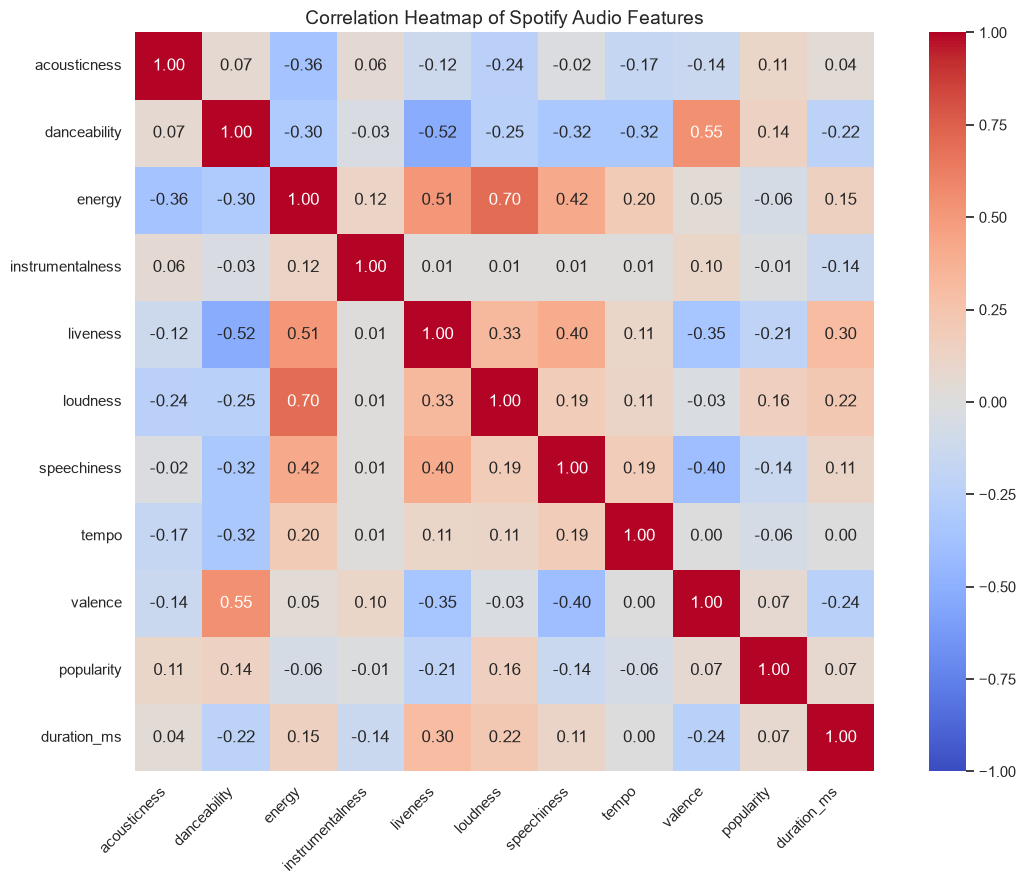

In [23]:
# Correlation analysis

correlation_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_ms"
]

# Calculate Pearson correlation coefficients
correlation_matrix = df_clean[
    correlation_features
].corr(method="pearson")

# Create the correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Correlation Heatmap of Spotify Audio Features",
    fontsize=14
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Correlation Analysis Findings

The correlation heatmap identified several relationships
between Spotify's audio characteristics.

Energy and loudness showed the strongest positive correlation
(r = 0.70), suggesting that more energetic recordings
generally tend to be louder.

Danceability and valence were moderately positively
correlated (r = 0.55), while danceability and liveness
showed a moderate negative relationship (r = -0.52).

Energy and liveness also showed a positive correlation
(r = 0.51).

When examining popularity, all audio features showed
relatively weak linear relationships. Liveness had the
strongest negative correlation with popularity (r = -0.21),
while loudness had the strongest positive correlation
(r = 0.16).

These findings suggest that no individual audio feature
strongly explains song popularity in this dataset.

The correlations will also help guide feature selection
by identifying variables that may contain overlapping
information before clustering.



### 3.6 Song Popularity Over Time

This analysis examines how average Spotify popularity
varies across album release years.

The release_year feature was extracted from release_date
during data preparation.

Because the dataset contains remastered albums, reissues,
and live performances, release_year does not necessarily
represent the original recording year.

The results therefore describe popularity patterns
associated with the listed Spotify album release dates.


In [ ]:
# Average song popularity by release year

# Group recordings by release year
from numpy import average


yearly_popularity = (
    df_clean.groupby("release_year")
    .agg(
        average_popularity=("popularity", "mean"),
        total_tracks=("id", "nunique")
    )
    .reset_index()

)